<a href="https://colab.research.google.com/github/Lakshmi-YL/dl-experiment/blob/main/dl_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#01
!pip install gensim

from gensim.models import Word2Vec

corpus = [
    ["machine", "learning", "is", "fun"],
    ["deep", "learning", "uses", "neural", "networks"],
    ["deep", "learning"]
]

model = Word2Vec(
    sentences=corpus,
    vector_size=50,
    window=2,
    min_count=1,
    workers=1
)

print("Embedding for 'learning':")
print(model.wv["learning"])

print("\nWords similar to 'learning':")
print(model.wv.most_similar("learning"))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 84.3 MB/s  0:00:00
Embedding for 'learning':
[-1.0724545e-03  4.7286271e-04  1.0206699e-02  1.8018546e-02
 -1.8605899e-02 -1.4233618e-02  1.2917745e-02  1.7945977e-02
 -1.0030856e-02 -7.5267432e-03  1.4761009e-02 -3.0669428e-03
 -9.0732267e-03  1.3108104e-02 -9.7203208e-03 -3.6320353e-03
  5.7531595e-03  1.9837476e-03 -1.6570430e-02 -1.8897636e-02
  1.4623532e-02  1.0140524e-02  1.3515387e-02  1.5257311e-03
  1.2701781e-02 -6.8107317e-03 -1.8928028e-03  1.1537147e-02
 -1.5043275e-02 -7.8722071e-03 -1.5023164e-02 -1.8600845e-03
  1.9076237e-02 -1.4638334e-02 -4.6675373e-03 -3.8754821e-03
  1.6154874e-02 -1.1861792e-02  9.0324880e-05 -9.5074680e-03
 -1.9207101e-02  1.0014586e-02 -1.7519170e-02 -8.7836506e-03
 -7.0199967e-05 -5.9236289e-04 -1.5322480e-02  1.9229487e-02
  9.9641159e-03  1.8466286e-02]

Words similar to 'learning':
[('machine', 0.13204392790794373), ('networks', 0.1267007291316986), ('deep', 0.042373016476631165), ('f

In [ ]:
#02
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = Sequential([
    Dense(16, activation='relu', input_shape=(4,)),
    Dense(12, activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=1)

loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)

print("\nPredicted Classes:", predicted_classes)
print("Actual Classes   :", y_test)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           204 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 415 (1.62 KB)

 Trainable params: 415 (1.62 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2833 - loss: 1.0786
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3917 - loss: 1.0661 
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4500 - loss: 1.0546 
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5750 - loss: 1.0391 
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5917 - loss: 1.0242 
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7250 - loss: 0.9995 
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8000 - loss: 0.9655 
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7917 - loss: 0.9167 
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8667 - loss: 0.8468 
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8750 - loss: 0.7729 
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8583 - loss: 0.7174 
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0

In [ ]:
#03
import numpy as np
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = x_train.reshape((-1, 28, 28, 1)).astype('float32') / 255.0
x_test = x_test.reshape((-1, 28, 28, 1)).astype('float32') / 255.0

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model.fit(x_train, y_train, epochs=10, batch_size=64, verbose=1)

loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {acc*100:.2f}%")

predictions = model.predict(x_test[:10])
print("Predicted classes:", np.argmax(predictions, axis=1))
print("Actual classes:", np.argmax(y_test[:10], axis=1))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 65s 68ms/step - accuracy: 0.9237 - loss: 0.2482
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 72s 77ms/step - accuracy: 0.9738 - loss: 0.0883
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 72s 67ms/step - accuracy: 0.9804 - loss: 0.0662
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 77s 82ms/step - accuracy: 0.9837 - loss: 0.0538
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 76s 76ms/step - accuracy: 0.9861 - loss: 0.0476
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 55s 47ms/step - accuracy: 0.9881 - loss: 0.0393
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 43s 46ms/step - accuracy: 0.9897 - loss: 0.0338
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 81s 45ms/step - accuracy: 0.9900 - loss: 0.0319
Epoch 9/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 42s 45ms/step - accuracy: 0.9913 - loss: 0.0273
Epoch 10/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 83s 45ms/step - accuracy: 0.9922 - loss: 0.0236
Test Accuracy: 99.29%
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
Predicted classes: [7 2 1 0 4 1 4 9 5 9]
Actual classes: [7

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.2777
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.1720
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.1439
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1284
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1182
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


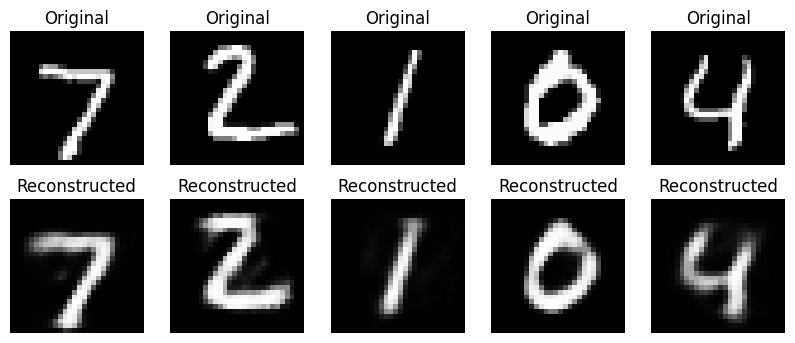

Original size: (10000, 784)
Compressed size: (10000, 32)


In [ ]:
#04
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Model

(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

input_img = layers.Input(shape=(784,))

encoded = layers.Dense(32, activation="relu")(input_img)

decoded = layers.Dense(784, activation="sigmoid")(encoded)

model = Model(input_img, decoded)

model.compile(optimizer="adam", loss="binary_crossentropy")

model.fit(x_train, x_train, epochs=5, batch_size=256)

encoder = Model(input_img, encoded)

encoded_imgs = encoder.predict(x_test)

decoded_imgs = model.predict(x_test)

n = 5

plt.figure(figsize=(10, 4))

for i in range(n):

    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.show()

print("Original size:", x_test.shape)
print("Compressed size:", encoded_imgs.shape)

In [ ]:
#05
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(
    num_words=10000
)

x_train = tf.keras.preprocessing.sequence.pad_sequences(
    x_train, maxlen=200
)

x_test = tf.keras.preprocessing.sequence.pad_sequences(
    x_test, maxlen=200
)

model = Sequential([
    Embedding(10000, 32),
    GlobalAveragePooling1D(),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy)

predictions = model.predict(x_test[:5])

print("\nReview Classification:")

for i in range(5):
    if predictions[i][0] >= 0.5:
        result = "Positive"
    else:
        result = "Negative"

    print("Review", i + 1, ":", result)
    print("Probability:", predictions[i][0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7735 - loss: 0.4695 - val_accuracy: 0.8720 - val_loss: 0.3148
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8889 - loss: 0.2714 - val_accuracy: 0.8724 - val_loss: 0.2996
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9144 - loss: 0.2143 - val_accuracy: 0.8790 - val_loss: 0.2990
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9289 - loss: 0.1829 - val_accuracy: 0.8828 - val_loss: 0.2992
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9437 - loss: 0.1532 - val_accuracy: 0.8354 - val_loss: 0.4599
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8222 - loss: 0.4797
Test Accuracy: 0.8222000002861023
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step

Review Classification:
Review 1 : Positive
Probability: 0.8832045
Review 2 : Positive
Probability: 0.9995293
Review 3 : Positive
Probability: 0.913539
Review 4 : Pos

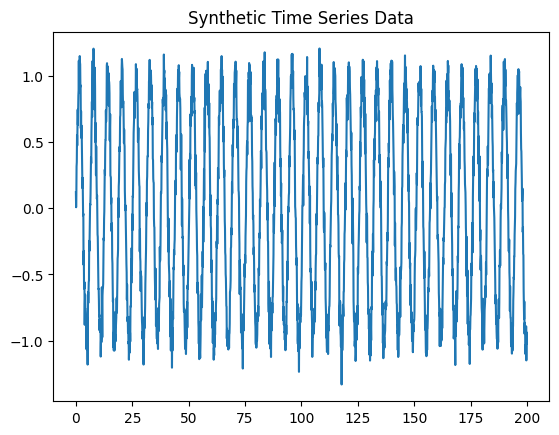

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.1106 - val_loss: 0.0282
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0133 - val_loss: 0.0038
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0032 - val_loss: 0.0027
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0025 - val_loss: 0.0026
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0022 - val_loss: 0.0020
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0021 - val_loss: 0.0019
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0021 - val_loss: 0.0020
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0021 - val_loss: 0.0020
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0020 - val_loss: 0.0019


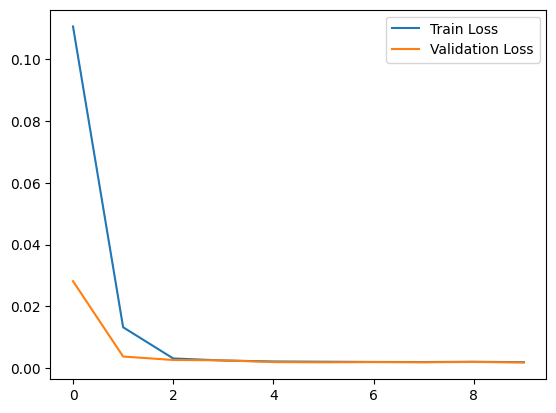

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step


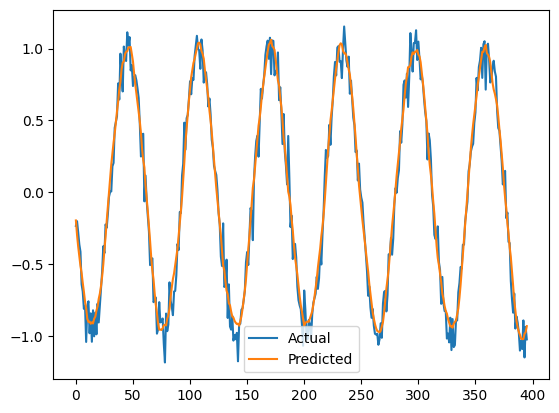

In [ ]:
#06
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

time = np.arange(0, 200, 0.1)
data = np.sin(time) + 0.1 * np.random.randn(len(time))
plt.plot(time, data)
plt.title("Synthetic Time Series Data")
plt.show()

scaler = MinMaxScaler(feature_range=(0, 1))
data_scaled = scaler.fit_transform(data.reshape(-1, 1))

def create_sequences(dataset, seq_length):
    X, y = [], []
    for i in range(len(dataset) - seq_length):
        X.append(dataset[i:i+seq_length, 0])
        y.append(dataset[i+seq_length, 0])
    return np.array(X), np.array(y)

SEQ_LEN = 20
X, y = create_sequences(data_scaled, SEQ_LEN)

X = X.reshape((X.shape[0], X.shape[1], 1))

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

model = Sequential([
    LSTM(50, activation='relu', input_shape=(SEQ_LEN, 1)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test), verbose=1)

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()

predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions.reshape(-1, 1))
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

plt.plot(y_test_actual, label='Actual')
plt.plot(predictions, label='Predicted')
plt.legend()
plt.show()

In [ ]:
#07
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

y_train = y_train.flatten()
y_test = y_test.flatten()

x_train = tf.image.resize(x_train, (96, 96))
x_test = tf.image.resize(x_test, (96, 96))

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy * 100, "%")

prediction = model.predict(x_test[:1])

classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

predicted_class = np.argmax(prediction)

print("Actual:", classes[y_test[0]])
print("Predicted:", classes[predicted_class])

train_accuracy = history.history["accuracy"][-1]
val_accuracy = history.history["val_accuracy"][-1]

print("Training Accuracy:", train_accuracy * 100, "%")
print("Validation Accuracy:", val_accuracy * 100, "%")

loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Accuracy:", test_accuracy * 100, "%")

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

In [ ]:
#08
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

reviews = [
    "I loved this movie, it was fantastic",
    "The product is excellent and very useful",
    "Amazing experience, I really enjoyed it",
    "The service was wonderful",
    "Very happy with my purchase",
    "This product is terrible",
    "I hated this movie",
    "Very disappointing experience",
    "The product broke after one day",
    "Poor quality and bad service"
]

labels = [
    1, 1, 1, 1, 1,
    0, 0, 0, 0, 0
]

X_train, X_test, y_train, y_test = train_test_split(
    reviews,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

vectorizer = TfidfVectorizer()

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

model = LogisticRegression()
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

new_reviews = [
    "The movie was amazing and I loved it",
    "The product was awful and disappointing",
    "I am very happy with this purchase"
]

new_reviews_tfidf = vectorizer.transform(new_reviews)
predictions = model.predict(new_reviews_tfidf)

for review, prediction in zip(new_reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print("\nReview:", review)
    print("Sentiment:", sentiment)


Review: The movie was amazing and I loved it
Sentiment: Positive

Review: The product was awful and disappointing
Sentiment: Positive

Review: I am very happy with this purchase
Sentiment: Negative
